# Exploration and sanity checks

This notebook looks at the data behind the project and checks the assumptions the pipeline relies on.
It reads the processed files written by `src/parse.py` and `src/features.py`, so run those first.
The headline analysis itself lives in `src/analysis.py`; the reasoning for each choice is in `docs/decisions.md`.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent  # this notebook lives in notebooks/
GAMES = (ROOT / "data/processed/games.parquet").as_posix()
PLAYER_GAMES = (ROOT / "data/processed/player_games.parquet").as_posix()

con = duckdb.connect()
sql = lambda q: con.sql(q).df()
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.spines.top": False, "axes.spines.right": False})

## 1. The dataset at a glance
One row per game. White wins slightly more often than Black, and draws are rare in fast online chess.

In [2]:
sql(f"""
SELECT count(*) AS games,
       min(start_time) AS first_game, max(start_time) AS last_game,
       round(100 * avg((result = '1-0')::INT), 1) AS white_wins_pct,
       round(100 * avg((result = '0-1')::INT), 1) AS black_wins_pct,
       round(100 * avg((result = '1/2-1/2')::INT), 1) AS draws_pct
FROM '{GAMES}'
""")

,games,first_game,last_game,white_wins_pct,black_wins_pct,draws_pct
0,11348506,2017-03-31 22:00:00,2017-04-30 21:59:59,49.7,46.5,3.8


## 2. Ratings
Ratings of both players in every game. The middle half of players is between about 1450 and 1835.

,count,mean,std,min,5%,25%,50%,75%,95%,max
elo,22697012.0,1644.0,282.0,696.0,1178.0,1451.0,1644.0,1835.0,2107.0,3082.0


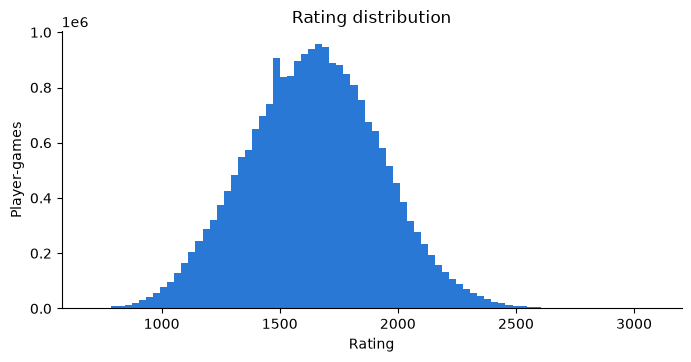

In [3]:
ratings = sql(f"SELECT white_elo AS elo FROM '{GAMES}' UNION ALL SELECT black_elo FROM '{GAMES}'")
ax = ratings.elo.plot.hist(bins=80, color="#2a78d6")
ax.set(xlabel="Rating", ylabel="Player-games", title="Rating distribution")
ratings.elo.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(0).to_frame().T

## 3. Game speeds
Lichess had no "Rapid" category in 2017, so speed is classified from the time control with Lichess's own
rule: estimated length = base time + 40 x increment (decision #4).

In [4]:
sql(f"""
WITH s AS (
  SELECT CASE WHEN base_seconds IS NULL THEN 'correspondence'
              WHEN base_seconds + 40 * increment_seconds < 30   THEN 'ultrabullet'
              WHEN base_seconds + 40 * increment_seconds < 180  THEN 'bullet'
              WHEN base_seconds + 40 * increment_seconds < 480  THEN 'blitz'
              WHEN base_seconds + 40 * increment_seconds < 1500 THEN 'rapid'
              ELSE 'classical' END AS speed
  FROM '{GAMES}')
SELECT speed, count(*) AS games, round(100 * count(*) / sum(count(*)) OVER (), 1) AS pct
FROM s GROUP BY 1 ORDER BY games DESC
""")

,speed,games,pct
0,blitz,5287959,46.6
1,bullet,2844321,25.1
2,rapid,2584704,22.8
3,ultrabullet,371052,3.3
4,classical,218979,1.9
5,correspondence,41491,0.4


## 4. Is the "time between games" estimate believable?
We estimate when each game's last move was played from the clock times (decision #5). Rematches are a
good test: a rematch can only start after the previous game is over, and clicking "rematch" takes a few
seconds. If the estimate were badly off, many rematch gaps would be negative.

In [5]:
gaps = sql(f"""
SELECT is_rematch, gap_minutes * 60 AS gap_seconds
FROM '{PLAYER_GAMES}' WHERE gap_minutes IS NOT NULL AND NOT is_tournament
""")
summary = gaps.groupby("is_rematch").gap_seconds.describe(percentiles=[0.01, 0.05, 0.25, 0.5]).round(0)
summary["pct_negative"] = gaps.groupby("is_rematch").gap_seconds.apply(lambda s: round(100 * (s < 0).mean(), 2))
summary.rename(index={True: "rematch", False: "new opponent"})

,count,mean,std,min,1%,5%,25%,50%,max,pct_negative
is_rematch,,,,,,,,,,
new opponent,10614683.0,20256.0,77783.0,-10513.0,19.0,28.0,56.0,224.0,2574516.0,0.08
rematch,2601723.0,666.0,18897.0,-2217.0,12.0,16.0,24.0,32.0,2524421.0,0.02


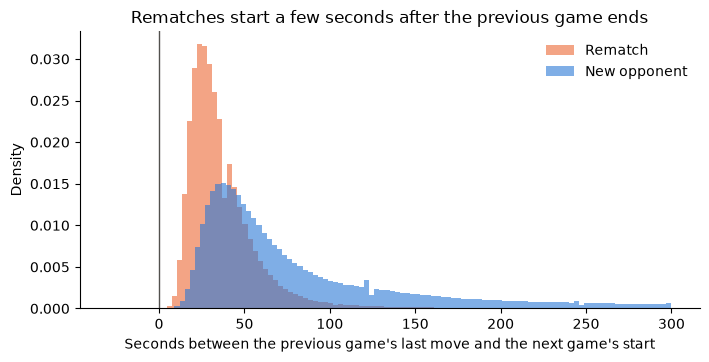

In [6]:
fig, ax = plt.subplots()
for rematch, label, color in [(True, "Rematch", "#eb6834"), (False, "New opponent", "#2a78d6")]:
    s = gaps.loc[gaps.is_rematch == rematch, "gap_seconds"]
    ax.hist(s[s.between(-30, 300)], bins=110, alpha=0.6, label=label, color=color, density=True)
ax.axvline(0, color="#52514e", lw=1)
ax.set(xlabel="Seconds between the previous game's last move and the next game's start", ylabel="Density",
       title="Rematches start a few seconds after the previous game ends")
ax.legend(frameon=False);

## 5. Why we can't use raw win rates
After a loss, players score less in their next game, but they also tend to face stronger opponents (rematches,
for example). The ratings already predict almost all of that drop, so the analysis measures performance
against the rating prediction instead.

In [7]:
sql(f"""
SELECT CASE prev_score WHEN 1 THEN 'after a win' WHEN 0 THEN 'after a loss' END AS previous_game,
       count(*) AS player_games,
       round(100 * avg(score), 1) AS actual_score_pct,
       round(100 * avg(expected_score), 1) AS expected_score_pct,
       round(avg(opp_elo - player_elo), 1) AS opponent_minus_player_rating
FROM '{PLAYER_GAMES}'
WHERE NOT is_tournament AND prev_is_clean AND NOT new_session AND prev_score IN (0, 1)
GROUP BY 1 ORDER BY 1 DESC
""")

,previous_game,player_games,actual_score_pct,expected_score_pct,opponent_minus_player_rating
0,after a win,4690494,53.6,53.2,-26.7
1,after a loss,4337161,46.9,46.8,26.7


## 6. How much does a loss move your rating?
This is the "rating mechanics" behind decisions #11 and #14: right after a loss your rating drops, before your
actual skill has changed, so a naive comparison makes players look *better* after losing.

,count,mean,std,min,25%,50%,75%,max
rating_diff,6404537.0,-12.7,17.7,-633.0,-12.0,-10.0,-8.0,41.0


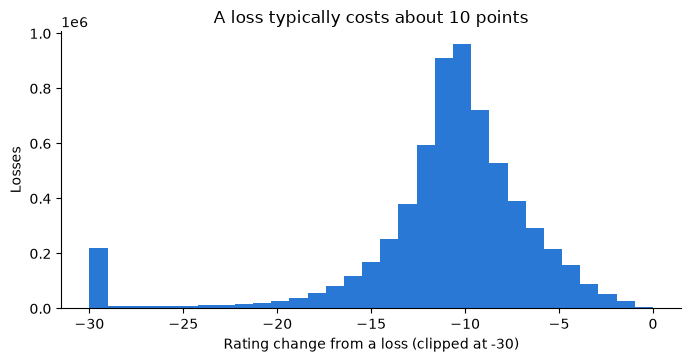

In [8]:
changes = sql(f"""
SELECT rating_diff FROM '{PLAYER_GAMES}' WHERE score = 0 AND NOT is_tournament AND rating_diff IS NOT NULL
""").rating_diff
ax = changes.clip(-30, 0).plot.hist(bins=31, color="#2a78d6")
ax.set(xlabel="Rating change from a loss (clipped at -30)", ylabel="Losses", title="A loss typically costs about 10 points")
changes.describe(percentiles=[0.25, 0.5, 0.75]).round(1).to_frame().T

## 7. Headline results
The main estimates, read from `results/models.csv` and converted to Elo points (how much weaker a player
would need to be to score that much less against an equal opponent).

In [9]:
import numpy as np

ELO = 400 / (np.log(10) * 0.25)
m = pd.read_csv(ROOT / "results/models.csv")
main = m[(m.rating_control == "own monthly average") & m.model.isin(["after_loss", "streak", "cooldown"]) &
         m.term.isin(["prev_loss", "streak_1", "streak_2", "streak_3", "streak_4", "streak_5plus",
                      "loss_x_gap_lt1", "loss_x_gap_30plus"])]
out = main.assign(elo=main.coef * ELO, ci_low=main.ci_low * ELO, ci_high=main.ci_high * ELO)
out[["model", "term", "elo", "ci_low", "ci_high", "pvalue", "n_obs"]].round(2)

,model,term,elo,ci_low,ci_high,pvalue,n_obs
0,after_loss,prev_loss,-6.90,-7.40,-6.40,0.00,9427840
13,streak,streak_1,-5.96,-6.50,-5.42,0.00,9427840
14,streak,streak_2,-6.82,-7.61,-6.03,0.00,9427840
15,streak,streak_3,-8.09,-9.26,-6.91,0.00,9427840
16,streak,streak_4,-11.54,-13.29,-9.79,0.00,9427840
17,streak,streak_5plus,-24.05,-26.59,-21.51,0.00,9427840
33,cooldown,loss_x_gap_lt1,-6.58,-7.25,-5.92,0.00,13209163
36,cooldown,loss_x_gap_30plus,-0.12,-0.82,0.58,0.73,13209163
